# FCOS — фінальне навчання

У попередніх експериментах найкращий результат FCOS отримала з learning rate `5e-5`. Тепер навчаємо модель на всіх train-відео, а після навчання перевіряємо її на окремому official validation. Зберігаємо ваги, метрики та графік loss, щоб передати результат команді.

## 1. Налаштування

Використовуємо вибрані параметри з cross-validation. Беремо кожен третій кадр із кожного train-відео, навчаємо вісім епох та зберігаємо checkpoint після кожної. За потреби навчання можна продовжити до десяти епох.

In [1]:
import json
import re
import time
import io
import contextlib
import random
import shutil
from collections import defaultdict
from pathlib import Path
from zipfile import ZipFile, ZIP_STORED, ZIP_DEFLATED

import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

SEED = 42
LR = 5e-5
EPOCHS = 8
TRAIN_FRAME_STEP = 3
BATCH_SIZE = 2
NUM_WORKERS = 0
NUM_CLASSES = 9

ROOT = Path('/kaggle/working/fcos_full_train')
ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Увімкни GPU в налаштуваннях Kaggle.'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
print('GPU:', torch.cuda.get_device_name(0))

GPU: Tesla T4


## 2. Дані

Завантажуємо підготовлені анотації та знаходимо зображення в Kaggle Inputs. Для train залишаємо кожен третій кадр окремо в кожній відеопослідовності. На official validation використовуємо всі 2 846 кадрів.

In [2]:
INPUT = Path('/kaggle/input')
annotations = [p.parent for p in INPUT.rglob('train.json') if (p.parent/'val.json').is_file()]
assert len(annotations) == 1, f'Неоднозначне розташування анотацій: {annotations}'
PREPROCESSED_ROOT = annotations[0]
train_data = json.loads((PREPROCESSED_ROOT/'train.json').read_text(encoding='utf-8'))
val_data = json.loads((PREPROCESSED_ROOT/'val.json').read_text(encoding='utf-8'))
assert len(train_data) == 24201 and len(val_data) == 2846

def images_root(split, sample):
    choices = [p for p in INPUT.rglob(split) if p.is_dir() and (p/sample).is_file()]
    assert len(choices) == 1, f'Не знайдено єдину папку {split}: {choices}'
    return choices[0]

TRAIN_ROOT = images_root('train', str(train_data[0]['file_name']).replace('\\', '/'))
VAL_ROOT = images_root('val', str(val_data[0]['file_name']).replace('\\', '/'))

def frame_key(rec):
    stem = Path(rec['file_name']).stem
    match = re.search(r'(\d+)$', stem)
    return (int(match.group(1)) if match else float('inf'), stem)

groups = defaultdict(list)
for rec in train_data:
    groups[Path(rec['file_name']).parent.as_posix()].append(rec)
train_records = [r for seq in sorted(groups) for r in sorted(groups[seq], key=frame_key)[::TRAIN_FRAME_STEP]]
val_records = val_data

print('Train:', len(train_records), 'frames from', len(groups), 'videos')
print('Official val:', len(val_records), 'frames')
print('Images:', TRAIN_ROOT, '|', VAL_ROOT)

Train: 8090 frames from 56 videos
Official val: 2846 frames
Images: /kaggle/input/datasets/alinabodnar05/multiple-object-video-detection-hw-2-ucu-ai-2026/train | /kaggle/input/datasets/alinabodnar05/multiple-object-video-detection-hw-2-ucu-ai-2026/val


## 3. Dataset і DataLoader

Під час навчання випадково віддзеркалюємо зображення по горизонталі. Для validation не застосовуємо аугментацію. Рамки об'єктів та ignored regions змінюються разом із зображеннями.

In [3]:
class DetectionDataset(Dataset):
    def __init__(self, records, images_root, train=False):
        self.images_root = Path(images_root)
        self.records = records
        transforms = [T.RandomHorizontalFlip(p=0.5)] if train else []
        transforms += [T.ToDtype(torch.float32, scale=True), T.ToPureTensor()]
        self.transforms = T.Compose(transforms)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        file_name = str(rec['file_name']).replace('\\', '/')
        with Image.open(self.images_root / file_name) as image:
            arr = np.asarray(image.convert('RGB')).copy()
        height, width = arr.shape[:2]
        image = tv_tensors.Image(torch.from_numpy(arr).permute(2, 0, 1))
        boxes = torch.as_tensor(rec['boxes'], dtype=torch.float32).reshape(-1, 4)
        ignored = torch.as_tensor(rec['ignored_boxes'], dtype=torch.float32).reshape(-1, 4)
        target = {
            'boxes': tv_tensors.BoundingBoxes(boxes, format='XYXY', canvas_size=(height, width)),
            'labels': torch.as_tensor(rec['labels'], dtype=torch.int64),
            'ignored_boxes': tv_tensors.BoundingBoxes(ignored, format='XYXY', canvas_size=(height, width)),
        }
        assert len(target['boxes']) == len(target['labels'])
        return self.transforms(image, target)

def collate_fn(items):
    return tuple(zip(*items))

train_loader = DataLoader(
    DetectionDataset(train_records, TRAIN_ROOT, train=True),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    DetectionDataset(val_records, VAL_ROOT, train=False),
    batch_size=1, shuffle=False, collate_fn=collate_fn,
    num_workers=NUM_WORKERS, pin_memory=True
)

print('Train batches:', len(train_loader),'| Val images:',len(val_loader))

Train batches: 4045 | Val images: 2846


## 4. Модель FCOS

Використовуємо FCOS ResNet50-FPN із COCO-pretrained вагами. Налаштовуємо класи під наш датасет та залишаємо ту саму обробку ignored regions, що й у попередніх експериментах.

In [4]:
from torchvision.models.detection import fcos_resnet50_fpn, FCOS_ResNet50_FPN_Weights
from torchvision.models.detection.fcos import FCOSClassificationHead
from torchvision.models.detection.transform import resize_boxes
from torchvision.ops import sigmoid_focal_loss


def create_model(pretrained=True):
    model = fcos_resnet50_fpn(
        weights=FCOS_ResNet50_FPN_Weights.DEFAULT if pretrained else None,
        weights_backbone=None,
    )
    anchors_per_loc = model.anchor_generator.num_anchors_per_location()[0]
    model.head.classification_head = FCOSClassificationHead(
        model.backbone.out_channels, anchors_per_loc, NUM_CLASSES
    )
    return model


def apply_ignore_handling(model):
    original_resize = model.transform.resize
    original_compute_loss = model.head.compute_loss

    def resize_with_ignore(image, target=None):
        original_size = tuple(image.shape[-2:])
        result_image, result_target = original_resize(image, target)
        if result_target is not None and 'ignored_boxes' in result_target:
            result_target['ignored_boxes'] = resize_boxes(
                result_target['ignored_boxes'], original_size, tuple(result_image.shape[-2:])
            )
        return result_image, result_target

    def loss_with_ignore(targets, outputs, anchors, matched_idxs):
        losses = original_compute_loss(targets, outputs, anchors, matched_idxs)
        cls_logits = outputs['cls_logits']
        neg_ignored_loss = cls_logits.sum() * 0.0
        num_foreground = sum(int((idx >= 0).sum().item()) for idx in matched_idxs)

        for i, target in enumerate(targets):
            ignored_boxes = target['ignored_boxes']
            if ignored_boxes.numel() == 0:
                continue
            anchor_centers = (anchors[i][:, :2] + anchors[i][:, 2:]) * 0.5
            inside = torch.zeros(len(anchor_centers), dtype=torch.bool,
                                 device=anchor_centers.device)
            for box in ignored_boxes:
                inside |= ((anchor_centers[:, 0] >= box[0]) &
                           (anchor_centers[:, 0] <= box[2]) &
                           (anchor_centers[:, 1] >= box[1]) &
                           (anchor_centers[:, 1] <= box[3]))
            inside &= (matched_idxs[i] < 0)
            if inside.any():
                logits = cls_logits[i][inside]
                neg_ignored_loss = neg_ignored_loss + sigmoid_focal_loss(
                    logits, torch.zeros_like(logits), reduction='sum'
                )
        losses['classification'] = losses['classification'] - neg_ignored_loss / max(1, num_foreground)
        return losses

    model.transform.resize = resize_with_ignore
    model.head.compute_loss = loss_with_ignore
    return model

## 5. Навчання

Зберігаємо checkpoint після кожної епохи. Якщо навчання перерветься, можна підключити останній checkpoint і продовжити з нього. Для нового запуску `RESUME_FROM` залишаємо `None`.

In [5]:
CHECKPOINT = ROOT/'full_latest.pth'
RESUME_FROM = None
CONFIG = {
    'model': 'FCOS ResNet50-FPN', 'pretrained': 'COCO',
    'learning_rate': LR, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'train_frame_step': TRAIN_FRAME_STEP, 'seed': SEED,
    'train_frames': len(train_records), 'val_frames': len(val_records),
    'classes': 8, 'ignored_regions': True,
}
(ROOT/'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')

if RESUME_FROM is not None and not CHECKPOINT.exists():
    shutil.copy2(RESUME_FROM, CHECKPOINT)

resume = CHECKPOINT.exists()
model = apply_ignore_handling(create_model(pretrained=not resume)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler('cuda')
start_epoch, loss_history = 0, []

if resume:
    ckpt = torch.load(CHECKPOINT, map_location='cpu', weights_only=True)
    assert ckpt['lr'] == LR and ckpt['train_frame_step'] == TRAIN_FRAME_STEP
    assert ckpt['batch_size'] == BATCH_SIZE and ckpt['epoch'] <= EPOCHS
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scaler.load_state_dict(ckpt['scaler'])
    start_epoch = ckpt['epoch']
    loss_history = list(ckpt['train_losses'])
    del ckpt
print('Starting at epoch', start_epoch + 1)

for epoch in range(start_epoch, EPOCHS):
    model.train()
    total_loss, n = 0.0, 0
    for images, targets in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False):
        images = [x.to(DEVICE, non_blocking=True) for x in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast('cuda'):
            loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss at epoch {epoch+1}')
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
        n += len(images)

    mean_loss = total_loss / n
    loss_history.append(mean_loss)
    state = {
        'epoch': epoch+1, 'model': model.state_dict(),
        'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
        'train_losses': loss_history, 'lr': LR,
        'batch_size': BATCH_SIZE, 'train_frame_step': TRAIN_FRAME_STEP,
    }
    tmp = CHECKPOINT.with_suffix('.tmp')
    torch.save(state, tmp)
    tmp.replace(CHECKPOINT)
    pd.DataFrame({'epoch': range(1, len(loss_history)+1), 'train_loss': loss_history}).to_csv(
        ROOT/'training_history.csv', index=False
    )
    print(f'Epoch {epoch+1}/{EPOCHS}: loss={mean_loss:.4f}', flush=True)

assert len(loss_history) == EPOCHS

Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /root/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:00<00:00, 240MB/s]


Starting at epoch 1


Epoch 1/8:   0%|          | 0/4045 [00:00<?, ?it/s]

Epoch 1/8: loss=1.0971


Epoch 2/8:   0%|          | 0/4045 [00:00<?, ?it/s]

... (9 outputs left out)

Epoch 7/8:   0%|          | 0/4045 [00:00<?, ?it/s]

Epoch 7/8: loss=0.8792


Epoch 8/8:   0%|          | 0/4045 [00:00<?, ?it/s]

Epoch 8/8: loss=0.8651


## 6. Оцінювання на official validation

Після навчання запускаємо inference на всіх кадрах official val та рахуємо COCO-метрики: mAP, AP50, AP75 і AP для різних розмірів об'єктів. Також зберігаємо передбачення та час inference, щоб можна було перевірити результат окремо.

In [6]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CLASS_NAMES = {1:'person', 2:'bicycle', 3:'car', 4:'van', 5:'truck',
               6:'tricycle', 7:'bus', 8:'motor'}

def xyxy_to_xywh(box):
    x1, y1, x2, y2 = map(float, box)
    return [x1, y1, max(0.0, x2-x1), max(0.0, y2-y1)]

def build_coco_gt(records):
    images, annotations = [], []
    ann_id = 1
    for rec in records:
        image_id = int(rec['image_id'])
        images.append({'id':image_id, 'file_name':rec['file_name']})
        for box, label in zip(rec['boxes'], rec['labels']):
            bbox = xyxy_to_xywh(box)
            if bbox[2] <= 0 or bbox[3] <= 0: continue
            annotations.append({
                'id':ann_id, 'image_id':image_id, 'category_id':int(label),
                'bbox':bbox, 'area':bbox[2]*bbox[3], 'iscrowd':0
            })
            ann_id += 1
        for box in rec['ignored_boxes']:
            bbox = xyxy_to_xywh(box)
            if bbox[2] <= 0 or bbox[3] <= 0: continue
            for label in CLASS_NAMES:
                annotations.append({
                    'id':ann_id, 'image_id':image_id, 'category_id':label,
                    'bbox':bbox, 'area':bbox[2]*bbox[3], 'iscrowd':1
                })
                ann_id += 1
    gt = COCO()
    gt.dataset = {
        'images':images, 'annotations':annotations,
        'categories':[{'id':k,'name':v} for k,v in CLASS_NAMES.items()],
        'info':{},'licenses':[]
    }
    gt.createIndex()
    return gt

def save_predictions(model, loader, records, folder):
    pred_path = folder / 'predictions_quick.json'
    time_path = folder / 'inference_times.json'
    if pred_path.is_file() and time_path.is_file():
        print('Predictions уже збережені:', folder)
        return
    model.eval()
    predictions, durations = [], []
    with torch.inference_mode():
        for k, (images, _) in enumerate(tqdm(loader, total=len(records), desc='Validation', leave=False)):
            imgs = [im.to(DEVICE, non_blocking=True) for im in images]
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            outputs = model(imgs)
            torch.cuda.synchronize()
            durations.append(time.perf_counter() - t0)
            for out in outputs:
                image_id = int(records[k]['image_id'])
                for box, label, score in zip(
                    out['boxes'].cpu().tolist(),
                    out['labels'].cpu().tolist(),
                    out['scores'].cpu().tolist(),
                ):
                    label = int(label)
                    if label not in CLASS_NAMES: continue
                    bbox = xyxy_to_xywh(box)
                    if bbox[2] <= 0 or bbox[3] <= 0: continue
                    predictions.append({
                        'image_id':image_id, 'category_id':label,
                        'bbox':bbox, 'score':float(score)
                    })
    pred_path.write_text(json.dumps(predictions), encoding='utf8')
    time_path.write_text(json.dumps({
        'seconds_per_image':durations,
        'images_evaluated':len(records)
    }), encoding='utf8')
    print('Predictions saved:', pred_path, '| detections:', len(predictions))

def score_predictions(folder, records):
    metrics_path = folder / 'metrics_quick.json'
    if metrics_path.is_file():
        return json.loads(metrics_path.read_text(encoding='utf8'))
    predictions = json.loads((folder/'predictions_quick.json').read_text(encoding='utf8'))
    times = json.loads((folder/'inference_times.json').read_text(encoding='utf8'))
    gt = build_coco_gt(records)
    if predictions:
        dt = gt.loadRes(predictions)
        ev = COCOeval(gt, dt, iouType='bbox')
        ev.params.imgIds = [int(r['image_id']) for r in records]
        ev.params.catIds = list(CLASS_NAMES)
        ev.params.maxDets = [1, 10, 100]
        with contextlib.redirect_stdout(io.StringIO()) as capture:
            ev.evaluate(); ev.accumulate(); ev.summarize()
        print(capture.getvalue().split('Average Precision')[1][:190].strip())
        values = [float(x) for x in ev.stats]
    else:
        values = [0.0] * 12
    ms = float(np.mean(times['seconds_per_image']) * 1000)
    metrics = {
        'mAP': values[0], 'AP50': values[1], 'AP75': values[2],
        'AP_small': values[3], 'AP_medium': values[4], 'AP_large': values[5],
        'inference_ms_per_image': ms,
        'FPS_equivalent_batch1': 1000.0/ms if ms > 0 else 0,
        'images_evaluated': len(records), 'num_predictions': len(predictions),
    }
    metrics_path.write_text(json.dumps(metrics, indent=2), encoding='utf8')
    print('Metrics saved:', metrics_path)
    return metrics
EVAL_META = ROOT/'evaluated_epoch.json'
previous_eval_epoch = None
if EVAL_META.is_file():
    previous_eval_epoch = json.loads(EVAL_META.read_text(encoding='utf-8')).get('epoch')
if previous_eval_epoch != EPOCHS:
    for name in ('predictions_quick.json','inference_times.json','metrics_quick.json'):
        (ROOT/name).unlink(missing_ok=True)

save_predictions(model,val_loader,val_records,ROOT)
metrics=score_predictions(ROOT,val_records)
EVAL_META.write_text(json.dumps({'epoch':EPOCHS},indent=2),encoding='utf-8')
print(pd.Series(metrics).to_string())

Validation:   0%|          | 0/2846 [00:00<?, ?it/s]

Predictions saved: /kaggle/working/fcos_full_train/predictions_quick.json | detections: 203039
creating index...
index created!
Loading and preparing results...
DONE (t=1.01s)
creating index...
index created!
(AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.132
Metrics saved: /kaggle/working/fcos_full_train/metrics_quick.json
mAP                            0.132367
AP50                           0.271539
AP75                           0.114144
AP_small                       0.065504
AP_medium                      0.119132
AP_large                       0.277170
inference_ms_per_image       203.994469
FPS_equivalent_batch1          4.902094
images_evaluated            2846.000000
num_predictions           203039.000000


## 7. Результати та архів

Будуємо графік training loss і зберігаємо ваги моделі окремо від повного checkpoint.

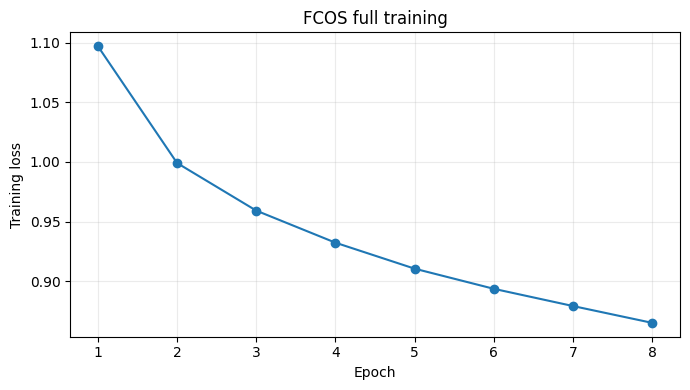

Saved: /kaggle/working/fcos_full_train_handoff.zip
Size: 496.3 MiB


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_history)+1), loss_history, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('FCOS full training')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(ROOT/'training_loss.png', dpi=160)
plt.show()

WEIGHTS = ROOT/'model_weights.pth'
torch.save({'model': model.state_dict(), 'epoch': EPOCHS, 'num_classes': 8}, WEIGHTS)

(ROOT/'README_handoff.md').write_text(
    '# FCOS full training\n\n'
    'Model: FCOS ResNet50-FPN, 8 classes (classification head: 9 channels).\n\n'
    'model_weights.pth — model state_dict for inference.\n\n'
    'full_latest.pth — model, optimizer, scaler and loss history for resuming training.\n\n'
    'metrics_quick.json — COCO evaluation on official validation.\n\n'
    'predictions_quick.json — validation predictions in COCO format.\n\n'
    'Create fcos_resnet50_fpn(weights=None, weights_backbone=None), replace its '
    'classification head with FCOSClassificationHead(backbone channels, anchors per location, 9), '
    'and load model_weights.pth["model"].\n',
    encoding='utf-8'
)

files = [
    CHECKPOINT, WEIGHTS, ROOT/'config.json', ROOT/'training_history.csv',
    ROOT/'training_loss.png', ROOT/'metrics_quick.json',
    ROOT/'predictions_quick.json', ROOT/'inference_times.json',
    ROOT/'README_handoff.md',
]
assert all(p.is_file() for p in files)
ARCHIVE = Path('/kaggle/working/fcos_full_train_handoff.zip')
with ZipFile(ARCHIVE, 'w', allowZip64=True) as archive:
    for path in files:
        archive.write(path, path.name, compress_type=ZIP_STORED if path.suffix == '.pth' else ZIP_DEFLATED)
print('Saved:', ARCHIVE)
print('Size: {:.1f} MiB'.format(ARCHIVE.stat().st_size / 2**20))